
# Student Performance Prediction

## 1. Project Overview

This project explores the use of machine learning to predict students' final mathematics grades based on demographic, social, and school-related information.

The goal is to build and evaluate regression models, compare their performance, and understand the limitations of predicting academic outcomes from student data.

## 2. Dataset

The dataset comes from the UCI Machine Learning Repository and contains information collected from two Portuguese secondary schools.

For this project, we use the mathematics dataset (`student-mat.csv`).

Dataset source: https://archive.ics.uci.edu/dataset/320/student+performance

## 3. Objective

- Explore and understand the dataset.
- Prepare features for machine learning.
- Train and compare regression models.
- Evaluate predictions using appropriate metrics.
- Analyze model limitations and document the findings.

## 4. Methodological Note

The target variable is `G3`, the final mathematics grade.

To make the prediction task more meaningful, we will exclude `G1` and `G2`, which represent grades from earlier periods. These variables are strongly associated with the final grade and could otherwise make the task unrealistically easy.

## 5. Tools

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn


In [2]:

import pandas as pd
import requests
import zipfile
from io import BytesIO

# Step 1: Download the dataset
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = requests.get(url, timeout=30)
response.raise_for_status()

# Step 2: Open the outer ZIP file
with zipfile.ZipFile(BytesIO(response.content)) as outer_archive:

    print("Files in outer archive:", outer_archive.namelist())

    # Step 3: Read the nested ZIP file
    nested_zip = outer_archive.read("student.zip")

    # Step 4: Open the inner ZIP file
    with zipfile.ZipFile(BytesIO(nested_zip)) as data_archive:

        print("Files in dataset:", data_archive.namelist())

        # Step 5: Find the mathematics dataset
        csv_path = next(
            name for name in data_archive.namelist()
            if name.endswith("student-mat.csv")
        )

        # Step 6: Load the dataset into a DataFrame
        with data_archive.open(csv_path) as file:
            df = pd.read_csv(file, sep=";")

# Step 7: Display basic information
print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Files in outer archive: ['.student.zip_old', 'student.zip']
Files in dataset: ['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:

# 1. Display all column names
print("Column names:")
print(df.columns.tolist())

# 2. Check data types and non-null values
print("\nDataset information:")
df.info()

# 3. Check missing values
print("\nMissing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

# 4. Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardi

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0



Number of duplicate rows:
0


In [4]:

# Statistical summary of the final grade
print("Statistical summary of G3:")
display(df["G3"].describe())

# Distribution of final grades
print("Number of students for each final grade:")
display(
    df["G3"]
    .value_counts()
    .sort_index()
    .rename_axis("Final Grade")
    .to_frame("Number of Students")
)


Statistical summary of G3:


,G3
count,395.000000
mean,10.415190
std,4.581443
min,0.000000
25%,8.000000
50%,11.000000
75%,14.000000
max,20.000000


Number of students for each final grade:


,Number of Students
Final Grade,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47


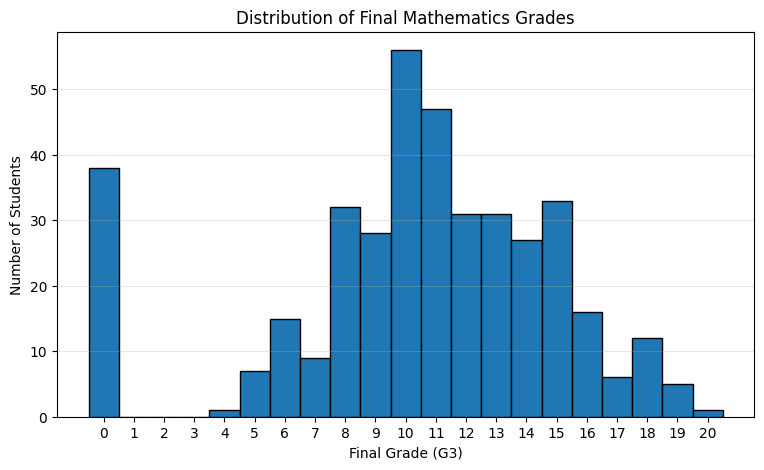

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    df["G3"],
    bins=range(0, 22),
    edgecolor="black",
    align="left"
)

plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.xticks(range(0, 21))
plt.grid(axis="y", alpha=0.3)

plt.show()


In [6]:

# Step 1: Define the target variable
y = df["G3"]

# Step 2: Create the input features
# Exclude G1, G2, and G3 from the inputs
X = df.drop(columns=["G1", "G2", "G3"])

# Step 3: Identify categorical and numerical features
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Step 4: Display the results
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumber of categorical features:",
      len(categorical_features))
print(categorical_features)

print("\nNumber of numerical features:",
      len(numerical_features))
print(numerical_features)


Features shape: (395, 30)
Target shape: (395,)

Number of categorical features: 17
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Number of numerical features: 13
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


In [7]:

from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display the shapes of the resulting datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (316, 30)
X_test shape: (79, 30)
y_train shape: (316,)
y_test shape: (79,)


In [8]:

import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Step 1: Prepare categorical and numerical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Step 2: Create the machine learning pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

# Step 3: Train the model
model.fit(X_train, y_train)

# Step 4: Predict grades for unseen test data
y_pred = model.predict(X_test)

# Step 5: Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("Model: Linear Regression")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")


Model: Linear Regression
MAE:  3.395
RMSE: 4.196
R²:   0.141


In [9]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Step 1: Create a simple baseline model
baseline_model = DummyRegressor(strategy="mean")

# Step 2: Train the baseline on the training data
baseline_model.fit(X_train, y_train)

# Step 3: Predict the grades in the test set
baseline_pred = baseline_model.predict(X_test)

# Step 4: Define a function to calculate evaluation metrics
def evaluate_model(y_true, predictions):
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2": r2_score(y_true, predictions)
    }

# Step 5: Compare both models on the same test set
results = pd.DataFrame({
    "Linear Regression": evaluate_model(y_test, y_pred),
    "Mean Baseline": evaluate_model(y_test, baseline_pred)
}).T

display(results.round(3))


,MAE,RMSE,R2
Linear Regression,3.395,4.196,0.141
Mean Baseline,3.646,4.550,-0.010


In [10]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Step 1: Prepare the preprocessing pipeline
rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Step 2: Create the Random Forest model
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=300,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Step 3: Train the model
random_forest_model.fit(X_train, y_train)

# Step 4: Make predictions
rf_pred = random_forest_model.predict(X_test)

# Step 5: Evaluate and compare all models
results = pd.DataFrame({
    "Mean Baseline": evaluate_model(y_test, baseline_pred),
    "Linear Regression": evaluate_model(y_test, y_pred),
    "Random Forest": evaluate_model(y_test, rf_pred)
}).T

display(results.round(3))


,MAE,RMSE,R2
Mean Baseline,3.646,4.550,-0.010
Linear Regression,3.395,4.196,0.141
Random Forest,3.027,3.793,0.298


In [11]:

from sklearn.model_selection import train_test_split, KFold, cross_validate

# Step 1: Create a fresh train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=123
)

# Step 2: Define five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Step 3: Define candidate models
candidate_models = {
    "Mean Baseline": baseline_model,
    "Linear Regression": model,
    "Random Forest": random_forest_model
}

# Step 4: Evaluate each model using training data only
cv_results = []

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

for name, estimator in candidate_models.items():

    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_mae"].mean(),
        "MAE Std": scores["test_mae"].std(),
        "Mean RMSE": -scores["test_rmse"].mean(),
        "Mean R2": scores["test_r2"].mean()
    })

# Step 5: Display the comparison
cv_table = pd.DataFrame(cv_results).set_index("Model")

display(cv_table.round(3))


,Mean MAE,MAE Std,Mean RMSE,Mean R2
Model,,,,
Mean Baseline,3.361,0.178,4.519,-0.009
Linear Regression,3.405,0.164,4.415,0.036
Random Forest,2.943,0.206,3.887,0.253


In [12]:

# Final evaluation on the new test set

final_models = {
    "Mean Baseline": baseline_model,
    "Linear Regression": model,
    "Random Forest": random_forest_model
}

final_results = []
final_predictions = {}

for name, estimator in final_models.items():
    estimator.fit(X_train, y_train)
    predictions = estimator.predict(X_test)

    final_predictions[name] = predictions

    metrics = evaluate_model(y_test, predictions)
    metrics["Model"] = name
    final_results.append(metrics)

final_results_df = (
    pd.DataFrame(final_results)
    .set_index("Model")
)

display(final_results_df.round(3))


,MAE,RMSE,R2
Model,,,
Mean Baseline,3.754,4.821,-0.026
Linear Regression,3.406,4.203,0.220
Random Forest,2.971,3.855,0.344


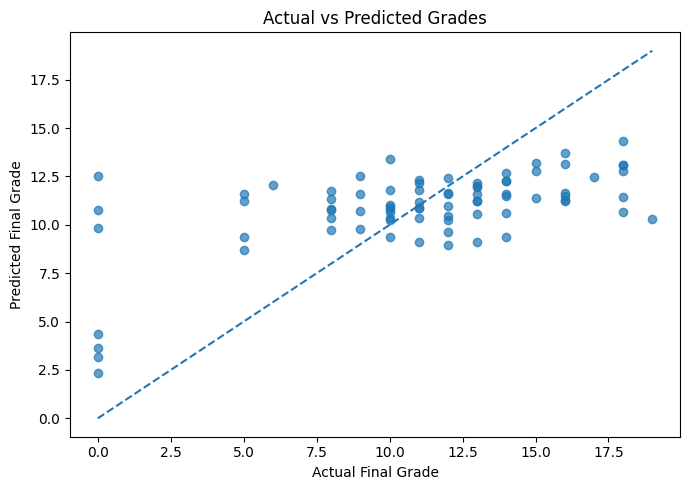

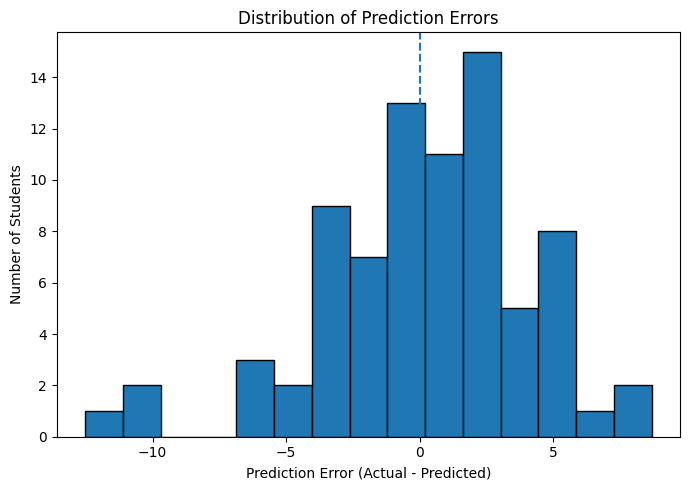

In [13]:

import matplotlib.pyplot as plt
import numpy as np

# Get final Random Forest predictions
rf_final_pred = final_predictions["Random Forest"]

actual = y_test.to_numpy()
residuals = actual - rf_final_pred

# Plot 1: Actual vs Predicted Grades
plt.figure(figsize=(7, 5))

plt.scatter(actual, rf_final_pred, alpha=0.7)

min_grade = min(actual.min(), rf_final_pred.min())
max_grade = max(actual.max(), rf_final_pred.max())

plt.plot(
    [min_grade, max_grade],
    [min_grade, max_grade],
    linestyle="--"
)

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Grades")
plt.tight_layout()
plt.show()

# Plot 2: Distribution of Prediction Errors
plt.figure(figsize=(7, 5))

plt.hist(residuals, bins=15, edgecolor="black")
plt.axvline(0, linestyle="--")

plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Number of Students")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.show()


,Feature,Importance
55,numerical__absences,0.1877
48,numerical__failures,0.1301
51,numerical__goout,0.0614
47,numerical__studytime,0.0392
50,numerical__freetime,0.0367
43,numerical__age,0.0359
54,numerical__health,0.0353
53,numerical__Walc,0.0349
45,numerical__Fedu,0.0322
46,numerical__traveltime,0.0299


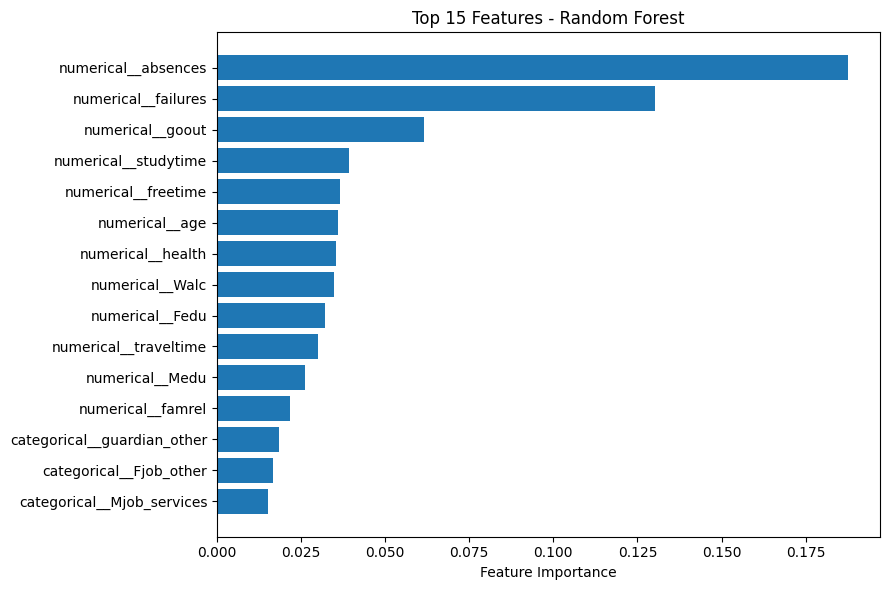

In [14]:

# Extract the trained preprocessing and regression steps
trained_preprocessor = random_forest_model.named_steps["preprocessor"]
trained_forest = random_forest_model.named_steps["regressor"]

# Get feature names after one-hot encoding
feature_names = trained_preprocessor.get_feature_names_out()

# Extract feature importance scores
importance = trained_forest.feature_importances_

# Create and sort the importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

# Display the top 15 features
display(importance_df.head(15).round(4))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Features - Random Forest")
plt.tight_layout()
plt.show()


In [15]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import shutil

# Create the project folder
project_dir = Path("student-performance-prediction")
results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Get the final predictions
actual = y_test.to_numpy()
rf_final_pred = final_predictions["Random Forest"]
residuals = actual - rf_final_pred

# 1. Save actual vs predicted plot
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(actual, rf_final_pred, alpha=0.7)

low = min(actual.min(), rf_final_pred.min())
high = max(actual.max(), rf_final_pred.max())

ax.plot([low, high], [low, high], linestyle="--")
ax.set_xlabel("Actual Final Grade")
ax.set_ylabel("Predicted Final Grade")
ax.set_title("Actual vs Predicted Grades")
fig.tight_layout()
fig.savefig(results_dir / "actual_vs_predicted.png", dpi=300)
plt.close(fig)

# 2. Save prediction error plot
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(residuals, bins=15, edgecolor="black")
ax.axvline(0, linestyle="--")
ax.set_xlabel("Prediction Error (Actual - Predicted)")
ax.set_ylabel("Number of Students")
ax.set_title("Distribution of Prediction Errors")
fig.tight_layout()
fig.savefig(results_dir / "prediction_errors.png", dpi=300)
plt.close(fig)

# 3. Save feature importance plot
top_features = importance_df.head(15).sort_values("Importance")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_features["Feature"], top_features["Importance"])
ax.set_xlabel("Feature Importance")
ax.set_title("Top 15 Features - Random Forest")
fig.tight_layout()
fig.savefig(results_dir / "feature_importance.png", dpi=300)
plt.close(fig)

# 4. Save tables as CSV files
final_results_df.to_csv(
    project_dir / "final_test_results.csv"
)

cv_table.to_csv(
    project_dir / "cross_validation_results.csv"
)

importance_df.to_csv(
    project_dir / "feature_importance.csv",
    index=False
)

# 5. Build Markdown tables for README
test_table = "\n".join(
    f"| {name} | {row['MAE']:.3f} | "
    f"{row['RMSE']:.3f} | {row['R2']:.3f} |"
    for name, row in final_results_df.iterrows()
)

cv_table_md = "\n".join(
    f"| {name} | {row['Mean MAE']:.3f} | "
    f"{row['Mean RMSE']:.3f} | {row['Mean R2']:.3f} |"
    for name, row in cv_table.iterrows()
)

top_features_md = "\n".join(
    f"- `{str(row['Feature']).replace('numerical__', '').replace('categorical__', '')}`: "
    f"{row['Importance']:.4f}"
    for _, row in importance_df.head(5).iterrows()
)

# 6. Create README.md
readme = f"""# Student Performance Prediction

A machine learning project that predicts students' final mathematics grades
using demographic, family, school, and lifestyle features.

## Project Objective

The goal is to explore student data, train regression models, compare their
performance, and analyze prediction errors and feature importance.

## Dataset

- Source: [UCI Student Performance Dataset](https://archive.ics.uci.edu/dataset/320/student+performance)
- File: `student-mat.csv`
- Samples: 395
- Original columns: 33
- Input features used: 30
- Target: `G3`, the final mathematics grade

The earlier grades `G1` and `G2` are excluded from the input features to avoid
relying directly on previous grades when predicting the final grade.

## Workflow

1. Download and load the dataset.
2. Explore columns, missing values, duplicates, and grade distributions.
3. Separate input features and target.
4. Split the data into training and testing sets.
5. Encode categorical features using One-Hot Encoding.
6. Train and compare regression models.
7. Evaluate models using MAE, RMSE, and R-squared.
8. Use five-fold cross-validation on the training set.
9. Analyze prediction errors and feature importance.

## Models

- Mean Baseline
- Linear Regression
- Random Forest Regressor

The Random Forest model uses 300 trees, a minimum leaf size of 2,
and a fixed random seed for reproducibility.

## Final Test Results

The following results are from the held-out test split.

| Model | MAE | RMSE | R-squared |
|---|---:|---:|---:|
{test_table}

Lower MAE and RMSE are better. Higher R-squared is generally better.

## Five-Fold Cross-Validation

Cross-validation results on the training set:

| Model | Mean MAE | Mean RMSE | Mean R-squared |
|---|---:|---:|---:|
{cv_table_md}

## Feature Importance

The five highest-ranked features in the fitted Random Forest model are:

{top_features_md}

Feature importance indicates how the model uses features. It does not
establish causal relationships.

## Visual Results

### Actual vs. Predicted Grades

![Actual vs predicted grades](results/actual_vs_predicted.png)

### Prediction Errors

![Prediction error distribution](results/prediction_errors.png)

### Feature Importance

![Feature importance](results/feature_importance.png)

## How to Run

1. Install the required libraries:

   `pip install -r requirements.txt`

2. Open `student_performance_prediction.ipynb` in Google Colab or Jupyter.
3. Run the notebook cells from top to bottom.

The notebook downloads the dataset from UCI, so an internet connection
is required.

## Limitations

- The dataset contains only 395 students from two Portuguese schools.
- The project focuses on mathematics grades and may not generalize to other
  subjects, schools, or populations.
- Predictions have noticeable errors, especially for some very low and high
  grades.
- Feature importance does not imply causation.
- This model is an educational project, not a tool for making decisions
  about individual students.

## Tools

Python, Pandas, NumPy, Matplotlib, Scikit-learn, and Requests.

## Dataset Reference

Cortez, P., & Silva, A. M. G. (2008).
Using data mining to predict secondary school student performance.
"""

(project_dir / "README.md").write_text(readme, encoding="utf-8")

# 7. Create requirements.txt
requirements = """pandas
numpy
matplotlib
scikit-learn
requests
"""

(project_dir / "requirements.txt").write_text(
    requirements, encoding="utf-8"
)

# 8. Create a ZIP package for download
zip_path = shutil.make_archive(
    str(project_dir),
    "zip",
    root_dir=project_dir.parent,
    base_dir=project_dir.name
)

print("Project files created successfully!")
print("\nFiles:")
for path in sorted(project_dir.rglob("*")):
    if path.is_file():
        print("-", path)

print("\nZIP package:", zip_path)

from google.colab import files
files.download(zip_path)


Project files created successfully!

Files:
- student-performance-prediction/README.md
- student-performance-prediction/cross_validation_results.csv
- student-performance-prediction/feature_importance.csv
- student-performance-prediction/final_test_results.csv
- student-performance-prediction/requirements.txt
- student-performance-prediction/results/actual_vs_predicted.png
- student-performance-prediction/results/feature_importance.png
- student-performance-prediction/results/prediction_errors.png

ZIP package: /content/student-performance-prediction.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>